# Solar-flare count spectra with GeD + BTO1 + BTO2

Predict the **expected measured count spectra and count rates** of a solar flare
with the COSI germanium detectors (GeD, Compton events) and both BTO detectors.
This notebook extends the existing COSIpy solar-count example. It uses standard
COSIpy for GeD and the public `bto_response` API for BTO; every scientific step is
visible below, with no imported project helper or configuration file.

The default interval is **2028-03-01 12:00--12:10 UTC** with a constant solar
photon template at scale 1. This is a simulated observing interval, not an
identified historical flare or a GOES-class calibration. No spectral fit or
Poisson realization is required for these mean count estimates.

## Inputs and where they enter

All inputs are below `project_path / "response"`; generated products go to
`project_path / "notebook_output" / "solar_counts"`. Use a kernel with COSIpy,
HistPy, NumPy, SciPy, Astropy, h5py, pandas and Matplotlib installed.

| Path variable | Contents and use |
|---|---|
| `input_spectrum_path` | `flx2tab_input.dat`: lower edge [keV], upper edge [keV], **integrated photon flux/bin** [ph cm$^{-2}$ s$^{-1}$]. There are 99,990 contiguous 0.1-keV bins from 1 to 10,000 keV. This is the same solar input as the original example. |
| `ged_response_path` | `SMEXv12.Continuum.HEALPixO3_10bins_log_flat.binnedimaging.imagingresponse.h5`: full GeD Compton response, with incident direction, true energy and measured `Em/Phi/PsiChi`. Its true-energy range is 100--10,000 keV. |
| `orientation_path` | `20280301_3_month_with_orbital_info.fits`: attitude, orbit and livetime used by both instruments. It is the legacy 550-km zenith-pointing history distributed with COSIpy. |
| `ged_background_path` | `Total_BG_3months_binned_for_continuum_filtered_with_SAAcut.hdf5`: **combined DC3 background**, unlike the albedo-only background used by the GRB notebooks. Only its measured-energy projection is used. |
| `bto_response_h5_path` | `bto_response_order2.h5`: unsmeared directional Geant4 deposit response for BTO1/BTO2, 15--3000 keV in true energy. Gain, resolution, threshold and saturation are applied explicitly below. |
| `bto_background_template_path` | `BTO_background_template_10-3000keV.fits`: time-independent single-BTO mean background from eleven simulation components, with its own energy boundaries. |

The BTO response and background are not distributed: obtain both from the BTO
team and place them in `response/`. The solar DAT and GeD total-background copy
are documented in `response/solar_input_manifest.json`; the original OSPEX
recipe and parameter notes are retained in `response/solar_model_provenance/`.

## What the photon template contains

The exported sum is nuclear de-excitation + neutron capture + annihilation/
positronium + thermal emission + a triple photon power law:

| Component | Parameters in the supplied OSPEX recipe |
|---|---|
| Broad + narrow nuclear de-excitation template | `f_template(..., 1, /brd_nar_nuc)` |
| Neutron-capture line | Gaussian: flux 3.55 ph cm$^{-2}$ s$^{-1}$, centroid 2223 keV, sigma 1 keV |
| 511-keV line + positronium continuum | `f_template(..., 0.2, /vern)` |
| Thermal continuum + lines | CHIANTI: EM $3.3\times10^{49}$ cm$^{-3}$, $kT=2.80$ keV |
| Triple photon power law | `[16, 1.5, 25, 3.2, 500, 2.3]`; breaks 25/500 keV and explicit pivot 50 keV |

We integrate these tabulated photons onto each instrument's true-energy bins.
This preserves narrow-line photons without asking a sparse callable quadrature
to find them. The response's coarse true-energy bins still limit line-response
accuracy. BTO does not include photons above 3 MeV, including their possible
partial-energy deposits; GeD extends to 10 MeV.

## Roadmap

1. Set paths, UTC interval, template scale, count windows and BTO detector effects.
2. Read the photon bins, select attitude, and obtain the apparent solar direction.
3. Build and fold the standard COSIpy GeD response; scale the DC3 total background.
4. Query BTO1 and BTO2 separately, apply detector effects, integrate the same
   solar photons, and add their regridded mean backgrounds.
5. Overplot source, background and total counts and count-rate density on each
   detector's native measured-energy grid; display band-integrated rates.

Source counts use **source-visible livetime**. Background counts use
**instrument livetime**, including when the source is occulted. Reported primary
rates are counts divided by elapsed duration. Detector presets remain placeholders;
rate-dependent dead time and pile-up are not applied.

## 1. Imports, project-relative paths and plotting style

Run from `tutorial/` or the `bto/` directory; otherwise set `project_path` explicitly.
The shared GeD response and history are reused from the other notebooks.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import astropy.units as u
from astropy.coordinates import SkyCoord, ICRS, UnitSphericalRepresentation, get_sun
from astropy.time import Time
from astropy.io import fits
from histpy import Histogram
from cosipy import SpacecraftHistory
from cosipy.response import FullDetectorResponse
from IPython.display import display

project_path = Path.cwd().resolve()
if project_path.name == 'tutorial':
    project_path = project_path.parent
if not (project_path / 'api' / 'bto_response.py').is_file():
    raise FileNotFoundError('Set project_path to the bto directory containing api/ and response/')
response_path = project_path / 'response'
sys.path.insert(0, str(project_path / 'api'))
from bto_response import (
    BTOCalibration, Prototype_Resolution,
    get_bto_response, write_ogip_response,
    get_bto_background, simulate_bto_spectrum,
)

input_spectrum_path = response_path / 'flx2tab_input.dat'
ged_response_path = response_path / 'SMEXv12.Continuum.HEALPixO3_10bins_log_flat.binnedimaging.imagingresponse.h5'
orientation_path = response_path / '20280301_3_month_with_orbital_info.fits'
ged_background_path = response_path / 'Total_BG_3months_binned_for_continuum_filtered_with_SAAcut.hdf5'
bto_response_h5_path = response_path / 'bto_response_order2.h5'
bto_background_template_path = response_path / 'BTO_background_template_10-3000keV.fits'
output_path = project_path / 'notebook_output' / 'solar_counts'
output_path.mkdir(parents=True, exist_ok=True)
for path in (input_spectrum_path, ged_response_path, orientation_path, ged_background_path,
             bto_response_h5_path, bto_background_template_path):
    if not path.is_file():
        raise FileNotFoundError(f'Missing input: {path}')

STYLE = {
    "font.family": "Times New Roman", "mathtext.fontset": "stix",
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.major.width": 1.5, "ytick.major.width": 1.5,
    "xtick.minor.width": 1.0, "ytick.minor.width": 1.0,
    "xtick.major.size": 10, "ytick.major.size": 10,
    "xtick.minor.size": 5, "ytick.minor.size": 5,
    "xtick.top": True, "ytick.right": True,
    "savefig.facecolor": "white", "font.size": 16,
    "axes.linewidth": 1.5, "legend.fancybox": False,
    "axes.spines.top": True, "axes.spines.right": True,
}
plt.rcParams.update(STYLE)
plt.rcParams.update({'axes.titlesize': 17, 'figure.titlesize': 18,
                     'axes.labelsize': 18, 'xtick.labelsize': 15, 'ytick.labelsize': 15,
                     'legend.fontsize': 13, 'figure.dpi': 140, 'savefig.dpi': 300})
def style_axes(ax):
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(1.5)
    ax.tick_params(which='both', direction='in', top=True, right=True)

11:47:50 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=14717616;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=14717617;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=14717625;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=14717626;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

11:47:51 WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=14717635;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=14717636;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

11:47:51 INFO      Starting 3ML!                                                                     ]8;id=14717645;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=14717646;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

WARNING   WARNINGs here are NOT errors                                                      ]8;id=14717654;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=14717655;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

...

WARNING   ROOT minimizer not available                                                ]8;id=14717682;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=14717683;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1208\1208]8;;\

WARNING   Multinest minimizer not available                                           ]8;id=14717691;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=14717692;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1218\1218]8;;\

WARNING   PyGMO is not available                                                      ]8;id=14717700;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=14717701;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1228\1228]8;;\

WARNING   Could not import plugin FermiLATLike.py. Do you have the relative instrument     ]8;id=14717709;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=14717710;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#126\126]8;;\
                  software installed and configured?                                                               

WARNING   No fermitools installed                                              ]8;id=14717719;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=14717720;file:///opt/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

## 2. Choose the time interval and solar direction

`start_utc` is **UTC**, and `duration_s` is elapsed time. The orientation covers
2028-03-01 01:35:00 through 2028-06-01 10:14:15 UTC. The midpoint Sun direction is
held fixed during this short flare; the spacecraft attitude still changes at each
time step.

`source_gl_gb_deg=None` uses the Sun. A tuple `(gl, gb)` selects a manual fixed
celestial direction instead. `flare_scale` multiplies the whole photon model;
it is not a conversion to a GOES X-class number.

`ged_count_range_keV` and `bto_count_range_keV` select **complete native measured-energy
bins** for rate totals. Actual selected boundaries are printed. The GeD default
retains the original 100--10,000 keV example; change it to select a different window.
`bto_plot_group` merges ADC channels only for display, preserving the selected counts.

In [2]:
start_utc = '2028-03-01T12:00:00'
duration_s = 600.0
flare_scale = 1.0
flux_kind = 'integrated'
source_gl_gb_deg = None       # Example: (61.699158, -55.130240)
earth_occultation = True
background_reference_exposure_s = None  # None: use the background Time-bin span

if not np.isfinite(duration_s) or duration_s <= 0:
    raise ValueError('duration_s must be positive and finite')
if not np.isfinite(flare_scale) or flare_scale < 0:
    raise ValueError('flare_scale must be nonnegative and finite')
tstart = Time(start_utc, format='isot', scale='utc')
tstop = tstart + duration_s*u.s
tmid = tstart + 0.5*duration_s*u.s
sun_gcrs = get_sun(tmid)
# Preserve apparent geocentric RA/Dec; rotate a direction, not the finite Sun position.
sun_coord = SkyCoord(ICRS(UnitSphericalRepresentation(lon=sun_gcrs.ra, lat=sun_gcrs.dec))).galactic
source_coord = sun_coord if source_gl_gb_deg is None else SkyCoord(
    l=source_gl_gb_deg[0]*u.deg, b=source_gl_gb_deg[1]*u.deg, frame='galactic'
)
# Endpoints quantify the small solar motion discarded by the midpoint approximation.
sun_endpoints_gcrs = get_sun(Time([tstart, tstop]))
sun_endpoints = SkyCoord(ICRS(UnitSphericalRepresentation(
    lon=sun_endpoints_gcrs.ra, lat=sun_endpoints_gcrs.dec
))).galactic
sun_motion_deg = sun_endpoints[0].separation(sun_endpoints[1]).deg
print(f'UTC: {tstart.utc.isot} — {tstop.utc.isot}')
print(f'Midpoint Sun: (gl, gb) = ({sun_coord.l.deg:.6f}, {sun_coord.b.deg:.6f}) deg')
print(f'Direction used:         ({source_coord.l.deg:.6f}, {source_coord.b.deg:.6f}) deg')
print(f'Solar motion during the interval: {sun_motion_deg:.6f} deg')
if sun_motion_deg > 0.1:
    print('For a long flare, divide the interval into shorter segments and update the Sun direction.')

# Count windows are measured energies, not incident-photon cutoffs.
ged_count_range_keV = (100.0, 10000.0)
bto_count_range_keV = (30.0, 2500.0)
bto_ids = ('BTO1', 'BTO2')
bto_plot_group = 16  # Display only; rates use the native channels.
bto_calibration = BTOCalibration(
    n_channels=4096, gain_quadratic_ch_per_keV2=0.0,
    gain_slope_ch_per_keV=1.0/0.8125, gain_offset_ch=0.0,
    lower_threshold_keV=30.0, upper_saturation_keV=3000.0,
)
bto_resolution = Prototype_Resolution
if not isinstance(bto_plot_group, int) or bto_plot_group < 1:
    raise ValueError('bto_plot_group must be a positive integer')

UTC: 2028-03-01T12:00:00.000 — 2028-03-01T12:10:00.000
Midpoint Sun: (gl, gb) = (61.699158, -55.130240) deg
Direction used:         (61.699158, -55.130240) deg
Solar motion during the interval: 0.006970 deg


## 3. Read the photon table and preserve its bin fluxes

The original table may contain narrow nuclear lines. We retain every input bin
instead of sampling a few energies. For an integrated-flux table,
$N_k=F_k/(E_{k,hi}-E_{k,lo})$. For a differential table,
$F_k=N_k(E_{k,hi}-E_{k,lo})$.

The first preview explicitly shows both quantities. No XSPEC table-model conversion
or custom spectral function is needed for this binned count calculation.

In [3]:
input_values = np.loadtxt(input_spectrum_path, ndmin=2)
if input_values.shape[1] != 3 or not np.all(np.isfinite(input_values)):
    raise ValueError('The photon input must contain exactly three finite numeric columns')
e_low, e_high, column3 = input_values.T
input_widths = e_high-e_low
if np.any(e_low <= 0) or np.any(input_widths <= 0) or np.any(column3 < 0):
    raise ValueError('Energies and widths must be positive; photon flux must be nonnegative')
if not np.allclose(e_high[:-1], e_low[1:], atol=1e-8, rtol=0):
    raise ValueError('Input energy bins must be ordered and contiguous')
if flux_kind == 'integrated':
    integrated_flux = column3.copy()
    photon_density = integrated_flux/input_widths
elif flux_kind == 'differential':
    photon_density = column3.copy()
    integrated_flux = photon_density*input_widths
else:
    raise ValueError('flux_kind must be integrated or differential')
input_centers = 0.5*(e_low+e_high)
preview = pd.DataFrame({'E_low_keV': e_low, 'E_high_keV': e_high,
                        'integrated_flux_ph_cm-2_s-1': integrated_flux,
                        'density_ph_cm-2_s-1_keV-1': photon_density})
display(preview.head())
print(f'{len(input_values):,} bins; {e_low[0]:g}–{e_high[-1]:g} keV')
print(f'Input-bin width: {input_widths.min():.4g}–{input_widths.max():.4g} keV')

,E_low_keV,E_high_keV,integrated_flux_ph_cm-2_s-1,density_ph_cm-2_s-1_keV-1
0,1.0,1.1,10134600.0,101346000.0
1,1.1,1.2,11648800.0,116488000.0
2,1.2,1.3,3721900.0,37219000.0
3,1.3,1.4,2835880.0,28358800.0
4,1.4,1.5,3581020.0,35810200.0


99,990 bins; 1–10000 keV
Input-bin width: 0.1–0.1 keV


## 4. Select the spacecraft history for the interval

The three-month orientation is about 548 MiB. Read only the rows bracketing the
chosen interval into a small FITS, then let COSIpy select the exact boundaries.
This retains the complete history in `response/` for trying other dates.

Instrument live time determines background accumulation. Source-visible live time
also includes Earth occultation and will be computed in Section 6.

In [4]:
selected_orientation_path = output_path / 'orientation_selected.fits'
with fits.open(orientation_path, memmap=True) as hdul:
    hdu = hdul[1]
    timestamps = hdu.data['TimeStamp']
    if hdu.header.get('VERSION') not in SpacecraftHistory.supported_file_versions:
        raise ValueError('The orientation file version is unsupported by this COSIpy environment')
    if tstart.unix < timestamps[0] or tstop.unix > timestamps[-1]:
        raise ValueError('The requested interval is outside the orientation coverage')
    first = max(0, int(np.searchsorted(timestamps, tstart.unix, side='right'))-1)
    last = min(len(timestamps), int(np.searchsorted(timestamps, tstop.unix, side='right'))+1)
    selected_hdu = fits.BinTableHDU(data=hdu.data[first:last].copy(), header=hdu.header.copy())
    fits.HDUList([fits.PrimaryHDU(header=hdul[0].header.copy()), selected_hdu]).writeto(
        selected_orientation_path, overwrite=True, checksum=True
    )
history = SpacecraftHistory.open(selected_orientation_path).select_interval(tstart, tstop)
livetime_s = float(history.cumulative_livetime().to_value(u.s))
if not np.isfinite(livetime_s) or livetime_s <= 0:
    raise ValueError('This interval has no instrument live time')
source_sc = history.get_target_in_sc_frame(source_coord)
x_pointing, y_pointing, z_pointing = history.attitude.transform_to('galactic').as_axes()
minutes = (history.obstime-tstart).to_value(u.min)
off_axis_deg = 90-source_sc.spherical.lat.deg
print(f'History: {history.npoints} samples, {history.nintervals} intervals')
print(f'Elapsed time = {duration_s:.3f} s; instrument live time = {livetime_s:.3f} s')
print(f'Source off-axis angle from +Z: {off_axis_deg[0]:.2f} deg at start, {off_axis_deg[-1]:.2f} deg at stop')

History: 601 samples, 600 intervals
Elapsed time = 600.000 s; instrument live time = 600.000 s
Source off-axis angle from +Z: 8.23 deg at start, 39.34 deg at stop


## 5. Locate the Sun on a Galactic Aitoff map

The gold star is the **actual Sun at the interval midpoint**. The colored track
is the **spacecraft +Z pointing during the interval**, not a moving Sun track.
The celestial Sun moves only about 0.007 degrees in the default 10 minutes,
while the spacecraft orientation changes appreciably.

Longitude increases to the left: the plotted coordinate is
$x=-\mathrm{wrap}_{180^\circ}(l)$ and $y=b$. The labels are Galactic longitude,
not the negative plotting coordinate. A manual source, if selected, is marked
separately from the Sun.

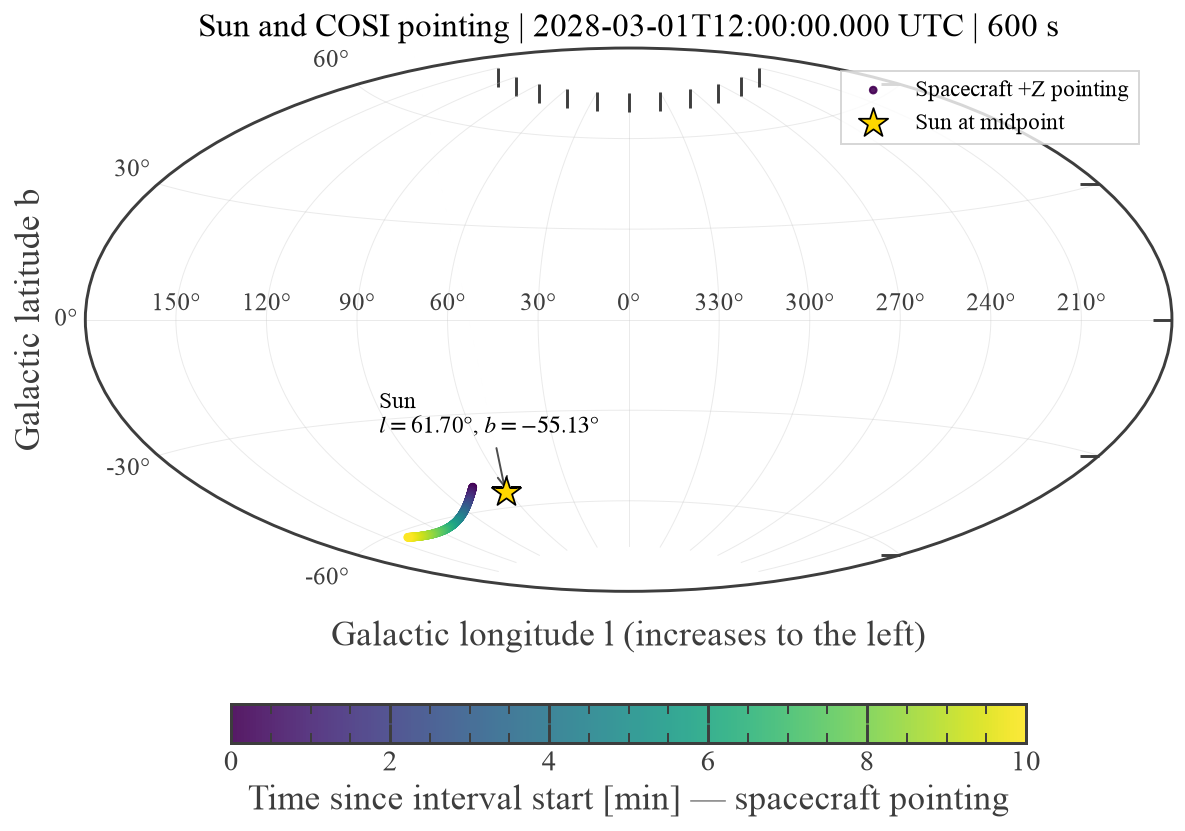

In [5]:
sun_map_x = -sun_coord.l.wrap_at(180*u.deg).rad
sun_map_y = sun_coord.b.rad
source_map_x = -source_coord.l.wrap_at(180*u.deg).rad
source_map_y = source_coord.b.rad
z_map_x = -z_pointing.l.wrap_at(180*u.deg).rad
z_map_y = z_pointing.b.rad

fig = plt.figure(figsize=(11, 5.8), constrained_layout=True)
ax = fig.add_subplot(111, projection='aitoff')
track = ax.scatter(z_map_x, z_map_y, c=minutes, cmap='viridis', s=12, alpha=0.9,
                   label='Spacecraft +Z pointing', zorder=3)
ax.scatter(sun_map_x, sun_map_y, marker='*', s=250, color='gold', edgecolor='black',
           linewidth=0.9, label='Sun at midpoint', zorder=5)
if source_gl_gb_deg is not None:
    ax.scatter(source_map_x, source_map_y, marker='x', s=90, color='tab:red',
               label='Manual source direction', zorder=6)
ax.annotate(f'Sun\n$l={sun_coord.l.deg:.2f}°$, $b={sun_coord.b.deg:.2f}°$',
            xy=(sun_map_x, sun_map_y), xytext=(-65, 30), textcoords='offset points',
            arrowprops={'arrowstyle': '->', 'color': '0.3'}, fontsize=12)
ax.set_xticks(np.deg2rad(np.arange(-150, 151, 30)))
ax.set_xticklabels(['150°','120°','90°','60°','30°','0°','330°','300°','270°','240°','210°'])
ax.set_yticks(np.deg2rad([-60, -30, 0, 30, 60]))
ax.tick_params(labelsize=13)
ax.grid(True, alpha=0.35)
ax.set_xlabel('Galactic longitude l (increases to the left)', labelpad=15)
ax.set_ylabel('Galactic latitude b')
ax.set_title(f'Sun and COSI pointing | {tstart.utc.isot} UTC | {duration_s:g} s')
ax.legend(loc='upper right', bbox_to_anchor=(0.98, 0.98), fontsize=12)
fig.colorbar(track, ax=ax, orientation='horizontal', shrink=0.52, pad=0.08,
             label='Time since interval start [min] — spacecraft pointing')
fig.savefig(output_path / '02_sun_galactic_aitoff.png', dpi=300)
fig.savefig(output_path / '02_sun_galactic_aitoff.pdf')
for axis in fig.axes:
    style_axes(axis)
plt.show()

## 6. Obtain the attitude-weighted COSIpy response

A fixed Galactic direction moves through the detector frame as the spacecraft
attitude changes. COSIpy's dwell map assigns visible live time to the neighboring
HEALPix response pixels. The point-source response sums those pixel responses
with their exposure weights, giving units **cm$^2$ s**.

Call `get_source_visibility` with a SkyCoord first, so the Earth test uses the
correct coordinate frame. Use those visible live times in a source-only history;
the original instrument live time remains available for the background.

The plot compares the actual Sun's small motion on the celestial sky with its
changing angle from spacecraft +Z. It always follows the actual Sun, even when
Section 2 selects a manual direction for count prediction.

Point-source response axes: ['Ei' 'Em' 'Phi' 'PsiChi'] | unit: cm2 s
Source-visible live time = 600.000 / 600.000 s


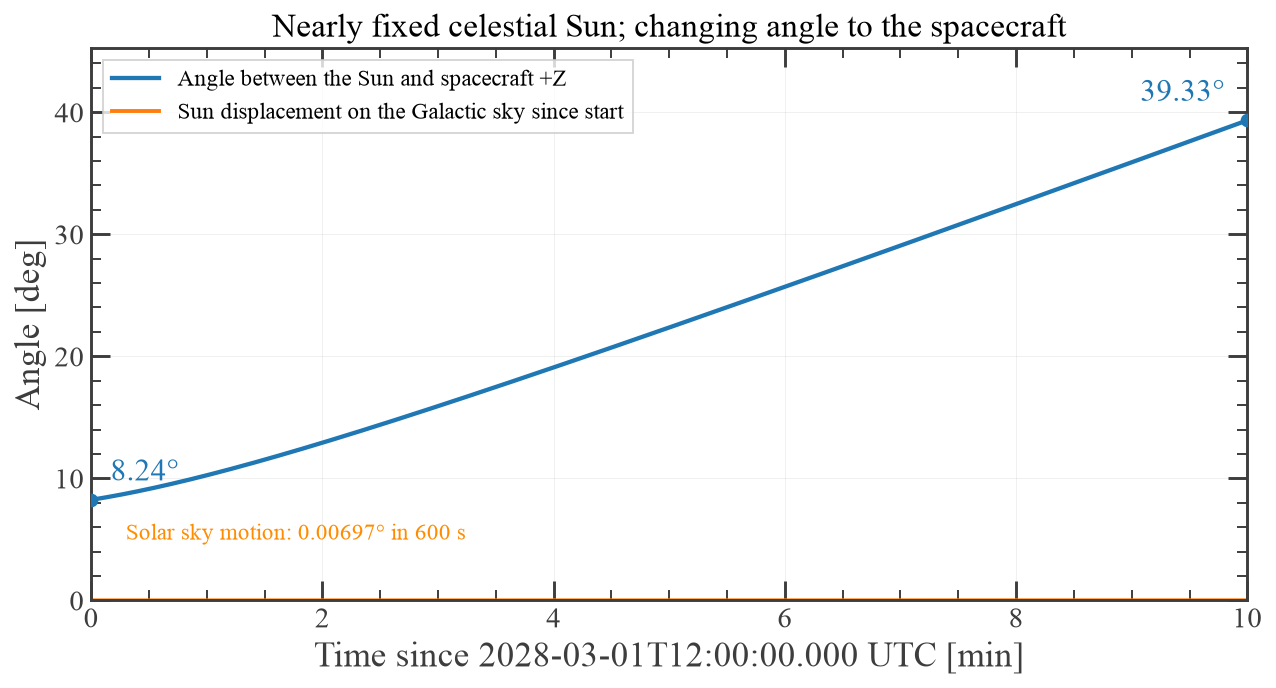

In [6]:
# Evaluate visibility with a SkyCoord before converting to response-direction pixels.
# This keeps the Earth test in its GCRS frame, independently of attitude axes.
source_visibility = history.get_source_visibility(source_coord if earth_occultation else None)
source_history = SpacecraftHistory(
    history.obstime, history.attitude, history.location, livetime=source_visibility
)
with FullDetectorResponse.open(ged_response_path, dtype=np.float64, cache_size=4) as response:
    ei_axis = response.axes['Ei'].copy()
    ei_edges = np.asarray(ei_axis.edges.to_value(u.keV), float)
    em_edges = np.asarray(response.axes['Em'].edges.to_value(u.keV), float)
    dwell_map = source_history.get_dwell_map(
        source_coord, base=response, interp=True, earth_occ=False
    )
    point_response = response.get_point_source_response(exposure_map=dwell_map)

visible_livetime_s = float(u.Quantity(dwell_map.data, dwell_map.unit).to_value(u.s).sum())
print('Point-source response axes:', point_response.axes.labels, '| unit:', point_response.unit)
print(f'Source-visible live time = {visible_livetime_s:.3f} / {livetime_s:.3f} s')

# A dedicated time-angle plot distinguishes solar sky motion from detector angle.
# Always show the actual Sun here, even if a manual source was chosen for folding.
sun_time_gcrs = get_sun(history.obstime)
sun_time_galactic = SkyCoord(ICRS(UnitSphericalRepresentation(
    lon=sun_time_gcrs.ra, lat=sun_time_gcrs.dec
))).galactic
sun_angle_from_Z_deg = z_pointing.separation(sun_time_galactic).deg
sun_sky_displacement_deg = sun_time_galactic.separation(sun_time_galactic[0]).deg

fig, ax = plt.subplots(figsize=(9.0, 4.8), constrained_layout=True)
ax.plot(minutes, sun_angle_from_Z_deg, color='tab:blue', lw=2.2,
        label='Angle between the Sun and spacecraft +Z')
ax.plot(minutes, sun_sky_displacement_deg, color='tab:orange', lw=2,
        label='Sun displacement on the Galactic sky since start')
ax.scatter(minutes[[0,-1]], sun_angle_from_Z_deg[[0,-1]], color='tab:blue', zorder=4)
ax.annotate(f'{sun_angle_from_Z_deg[0]:.2f}°', xy=(minutes[0],sun_angle_from_Z_deg[0]),
            xytext=(10,10), textcoords='offset points', color='tab:blue')
ax.annotate(f'{sun_angle_from_Z_deg[-1]:.2f}°', xy=(minutes[-1],sun_angle_from_Z_deg[-1]),
            xytext=(-55,10), textcoords='offset points', color='tab:blue')
ax.text(0.03,0.11, f'Solar sky motion: {sun_sky_displacement_deg[-1]:.5f}° in {duration_s:g} s',
        transform=ax.transAxes, fontsize=12, color='darkorange')
ax.set(xlabel=f'Time since {tstart.utc.isot} UTC [min]', ylabel='Angle [deg]',
       xlim=(0, duration_s/60), ylim=(0,max(45,float(sun_angle_from_Z_deg.max())*1.15)),
       title='Nearly fixed celestial Sun; changing angle to the spacecraft')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=12)
fig.savefig(output_path / '03_sun_angle_vs_time.png', dpi=300)
fig.savefig(output_path / '03_sun_angle_vs_time.pdf')
for axis in fig.axes:
    style_axes(axis)
plt.show()

## 7. Rebin the photon spectrum onto the true-energy response bins

Each original bin is treated as constant photon density across its width.
The overlap integral preserves its photons, including narrow-line bins:

$$f_i=\mathrm{flare\_scale}\sum_k N_k
\max\big[0,\min(E_{k,hi},E_{i,hi})-\max(E_{k,lo},E_{i,lo})\big].$$

This gives **bin-integrated** flux, so the later count convolution must not
multiply by $\Delta E_i$ again. The turquoise stairs show the response-bin average
$f_i/\Delta E_i$. They illustrate how much spectral detail is lost in the ten coarse
response bins. This averaging preserves photons, not the original narrow-line
profile or a finely sampled energy-dependent response.

Photon flux over 100–10000 keV = 29.5608376 ph cm^-2 s^-1


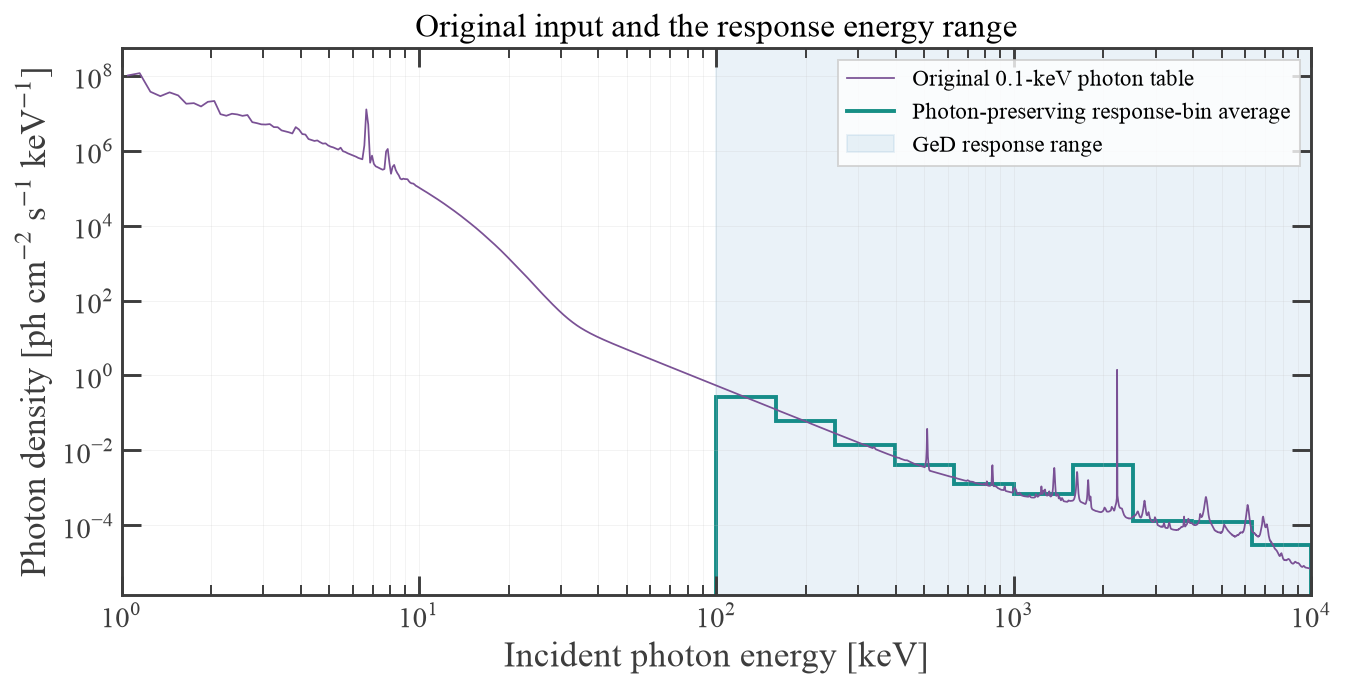

In [7]:
photon_flux_ei = np.zeros(len(ei_edges)-1)
for i, (lo, hi) in enumerate(zip(ei_edges[:-1], ei_edges[1:])):
    overlap_keV = np.maximum(np.minimum(e_high, hi)-np.maximum(e_low, lo), 0)
    photon_flux_ei[i] = flare_scale*np.sum(photon_density*overlap_keV)
response_range_overlap = np.maximum(np.minimum(e_high, ei_edges[-1])-np.maximum(e_low, ei_edges[0]), 0)
input_flux_in_range = flare_scale*np.sum(photon_density*response_range_overlap)
np.testing.assert_allclose(photon_flux_ei.sum(), input_flux_in_range, rtol=1e-10, atol=1e-12)
print(f'Photon flux over 100–10000 keV = {photon_flux_ei.sum():.7f} ph cm^-2 s^-1')

response_bin_density = photon_flux_ei/np.diff(ei_edges)

fig, ax = plt.subplots(figsize=(9.5, 4.8), constrained_layout=True)
ax.plot(input_centers, photon_density*flare_scale, color='#7A5195', lw=0.9,
             label='Original 0.1-keV photon table')
ax.stairs(response_bin_density, ei_edges, color='#168F85', lw=2,
               label='Photon-preserving response-bin average')
ax.axvspan(ei_edges[0], ei_edges[-1], color='tab:blue', alpha=0.09,
                label='GeD response range')
ax.set(xscale='log', yscale='log', xlim=(e_low[0], e_high[-1]),
            xlabel='Incident photon energy [keV]',
            ylabel=r'Photon density [ph cm$^{-2}$ s$^{-1}$ keV$^{-1}$]',
            title='Original input and the response energy range')
ax.legend(fontsize=12, loc='upper right')

ax.grid(True, which='both', alpha=0.2)
fig.savefig(output_path / '01_photon_spectrum_and_response_range.png', dpi=300)
fig.savefig(output_path / '01_photon_spectrum_and_response_range.pdf')
for axis in fig.axes:
    style_axes(axis)
plt.show()

## 8. Effective area and Energy Redistribution

The matrix $K_{ij}$ [cm$^2$ s] is the energy projection of the point-source response.
Its row sum is area × exposure. We display:

$$\overline A_i=\frac{\sum_j K_{ij}}{T_{elapsed}},\qquad
P_{ij}=P(E_m\in j\mid E_i\in i,\mathrm{detected})=
\frac{K_{ij}}{\sum_j K_{ij}}.$$

$\overline A$ includes live-time losses and Earth occultation; it is averaged over
**elapsed time**. $P$ is a probability **per measured-energy bin**, not per keV;
each nonzero row sums to one. Its rows are true-energy bins and its columns are
measured-energy bins. Cells to the left of the diagonal represent lower measured energy
than the incident photon energy. The ten-bin response does not resolve a narrow
solar line or model the response at every 0.1-keV input point.

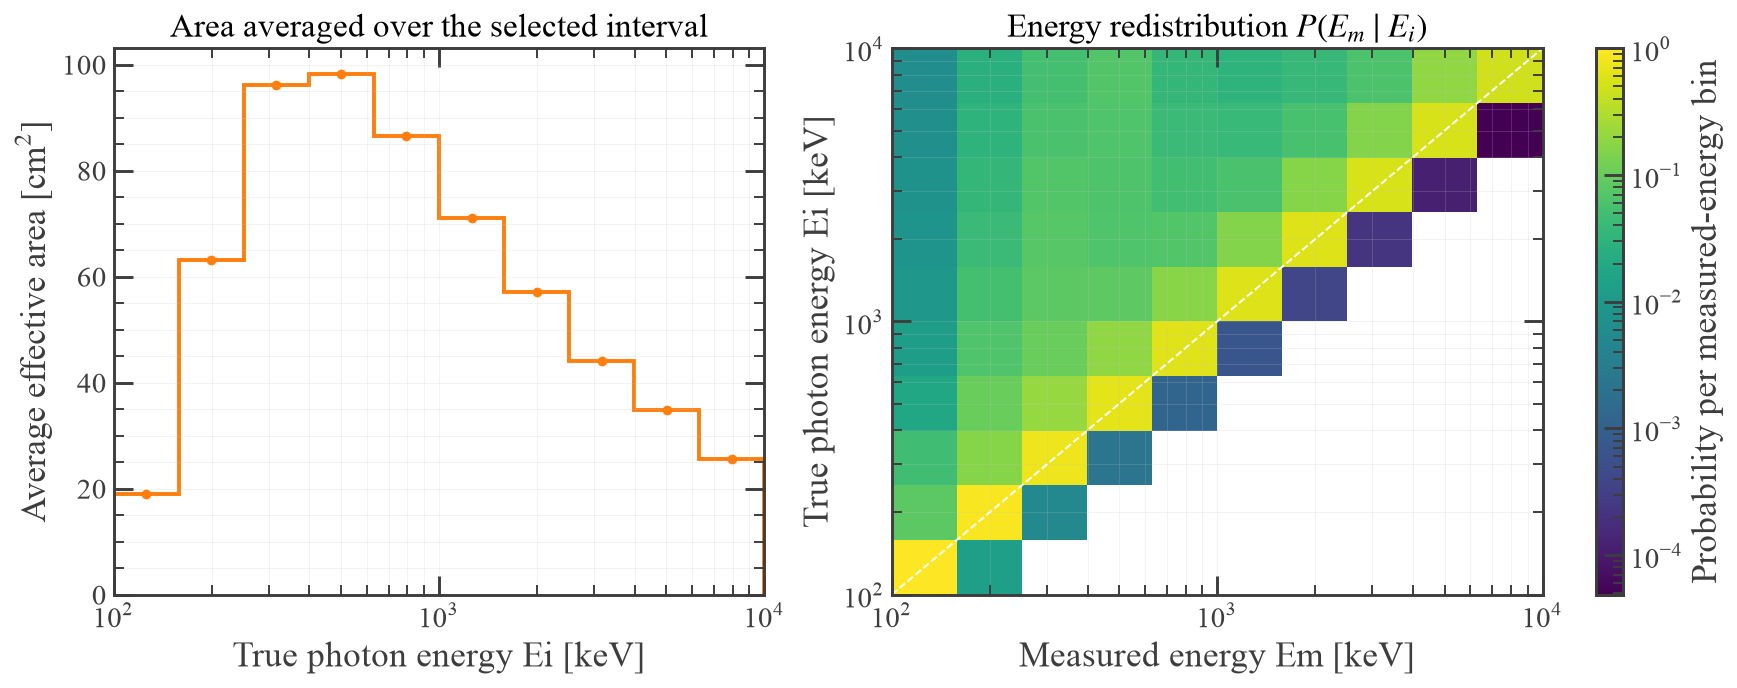

In [8]:
# Sum all Compton-angle bins; the retained matrix has Ei rows and Em columns.
spectral_projection = point_response.project(['Ei', 'Em']).to_dense()
if list(spectral_projection.axes.labels) != ['Ei', 'Em']:
    raise ValueError('Unexpected spectral-response axis order')
area_exposure_cm2_s = np.asarray(spectral_projection.contents.to_value(u.cm**2*u.s), float)
area_exposure_by_ei = area_exposure_cm2_s.sum(axis=1)
mean_response_cm2 = area_exposure_cm2_s/duration_s
mean_aeff_cm2 = area_exposure_by_ei/duration_s

dispersion_probability = np.divide(
    area_exposure_cm2_s, area_exposure_by_ei[:, None],
    out=np.zeros_like(area_exposure_cm2_s), where=area_exposure_by_ei[:, None] > 0
)
nonzero_rows = area_exposure_by_ei > 0
np.testing.assert_allclose(dispersion_probability[nonzero_rows].sum(axis=1), 1.0, rtol=1e-12)
ei_centers = np.sqrt(ei_edges[:-1]*ei_edges[1:])

fig, axes = plt.subplots(1, 2, figsize=(12.3, 4.8), constrained_layout=True)
axes[0].stairs(mean_aeff_cm2, ei_edges, color='tab:orange', lw=2)
axes[0].plot(ei_centers, mean_aeff_cm2, 'o', color='tab:orange', ms=4)
axes[0].set(xscale='log', xlim=(ei_edges[0], ei_edges[-1]), ylim=(0, None),
            xlabel='True photon energy Ei [keV]', ylabel=r'Average effective area [cm$^2$]',
            title='Area averaged over the selected interval')
positive_probabilities = dispersion_probability[dispersion_probability > 0]
probability_norm = LogNorm(vmin=max(positive_probabilities.min(), 1e-6), vmax=1) if positive_probabilities.size else None
mesh = axes[1].pcolormesh(em_edges, ei_edges, np.ma.masked_equal(dispersion_probability, 0),
                         norm=probability_norm, cmap='viridis', shading='flat')
axes[1].plot([em_edges[0], em_edges[-1]], [ei_edges[0], ei_edges[-1]], 'w--', lw=1.0)
axes[1].set(xscale='log', yscale='log', xlabel='Measured energy Em [keV]',
            ylabel='True photon energy Ei [keV]', title=r'Energy redistribution $P(E_m\mid E_i)$')
fig.colorbar(mesh, ax=axes[1], label='Probability per measured-energy bin')
for ax in axes: ax.grid(True, which='both', alpha=0.2)
fig.savefig(output_path / '04_effective_area_and_dispersion.png', dpi=300)
fig.savefig(output_path / '04_effective_area_and_dispersion.pdf')
for axis in fig.axes:
    style_axes(axis)
plt.show()
# Keep the exposure-valued GeD matrix distinct from the BTO area matrices.
ged_area_exposure_cm2_s = area_exposure_cm2_s.copy()


## 9. Fold the solar photon spectrum with the full response

Construct a HistPy `Ei` histogram with the integrated flux in units
ph cm$^{-2}$ s$^{-1}$. COSIpy's public
`point_response.get_expectation(None, flux=...)` accepts this already integrated
flux directly and predicts counts in every `Em/Phi/PsiChi` bin. Summing the
Compton-angle dimensions produces the measured-energy spectrum.

$$S_j=\sum_i f_i K_{ij}.$$

The precomputed-flux argument avoids introducing a custom spectral function or
numerically integrating narrow lines. This uses COSIpy's point-source folding
operation, also used by source-injection workflows.

In [9]:
flux_histogram = Histogram([ei_axis], contents=photon_flux_ei, unit=1/(u.cm**2*u.s))
expected_source_cds = point_response.get_expectation(None, flux=flux_histogram)
expected_source_em = expected_source_cds.project('Em').to_dense()
signal_counts = np.asarray(expected_source_em.contents, float)
# Equivalent visible matrix multiplication checks the public full-CDS folding.
signal_counts_matrix = photon_flux_ei @ area_exposure_cm2_s
np.testing.assert_allclose(signal_counts, signal_counts_matrix, rtol=1e-10, atol=1e-8)
print(f'Expected source counts = {signal_counts.sum():,.3f}')
print(f'Source rate over elapsed time = {signal_counts.sum()/duration_s:,.4f} counts/s')

Expected source counts = 753,957.908
Source rate over elapsed time = 1,256.5965 counts/s


## 10. Scale the DC3 total background to the observation

The background has one Time bin. We cannot extract a local 10-minute background
from it. Project all its angular bins onto `Em` and calculate

$$b_j=\frac{N_j^{BG}}{T_{BG,ref}},\qquad B_j=b_jT_{live}.$$

The default $T_{BG,ref}=7,979,955$ s is the full Time-bin span. Because the file is
SAA-cut and contains no exact post-cut effective exposure, this is a simple mean-rate
normalization. Supply `background_reference_exposure_s` when a verified effective
exposure is available. Background accumulates for instrument live time, even when
the Sun is occulted. Do not multiply the background by source-visible live time.

The background has 30 `Phi` bins and Galactic `PsiChi`, whereas this response has
36 `Phi` bins and spacecraft `PsiChi`. Only their **energy projections** are added.
Their ten `Em` boundaries must match; their full CDS histograms must not be added.

In [10]:
background_histogram = Histogram.open(ged_background_path)
bg_time_edges = np.asarray(background_histogram.axes['Time'].edges.to_value(u.s), float)
if len(bg_time_edges) != 2:
    raise ValueError('This tutorial expects one background Time bin')
if tstart.unix < bg_time_edges[0] or tstop.unix > bg_time_edges[-1]:
    raise ValueError('The interval is outside the background reference epoch')
background_span_s = float(bg_time_edges[-1]-bg_time_edges[0])
background_reference_s = (background_span_s if background_reference_exposure_s is None
                          else float(background_reference_exposure_s))
if not np.isfinite(background_reference_s) or background_reference_s <= 0:
    raise ValueError('The background reference exposure must be positive and finite')
background_em = background_histogram.project('Em').to_dense()
background_em_edges = np.asarray(background_em.axes['Em'].edges.to_value(u.keV), float)
if background_em_edges.shape != em_edges.shape or not np.allclose(background_em_edges, em_edges, atol=1e-6, rtol=1e-8):
    raise ValueError('Source and background Em boundaries differ')
background_reference_counts = np.asarray(background_em.contents, float)
if np.any(background_reference_counts < 0) or not np.all(np.isfinite(background_reference_counts)):
    raise ValueError('Invalid background counts')
background_rate = background_reference_counts/background_reference_s
background_counts = background_rate*livetime_s
total_counts = signal_counts+background_counts
print('Background axes:', background_histogram.axes.labels, '| shape:', background_histogram.axes.shape)
print(f'Three-month total: {background_reference_counts.sum():,.0f} counts')
print(f'Reference exposure: {background_reference_s:,.3f} s')
print(f'Mean total-background rate: {background_rate.sum():.5f} counts / live second')
print(f'Expected background during the interval: {background_counts.sum():,.3f} counts')

Background axes: ['Time' 'Em' 'Phi' 'PsiChi'] | shape: (1, 10, 30, 768)
Three-month total: 235,566,101 counts
Reference exposure: 7,979,955.000 s
Mean total-background rate: 29.51973 counts / live second
Expected background during the interval: 17,711.837 counts


## 11. Build the BTO1 and BTO2 responses for the same Sun and interval

The API averages directional deposit matrices with visible-livetime weights and
then applies the gain, threshold, saturation and Gaussian resolution. Its
`rsp_cm2[Etrue, channel]` is an **area**, normalized per source-visible second;
the GeD point-source response above already has units **area × exposure**.

Write the source-specific OGIP files for later reuse. There is no second
application of resolution. The two detectors are queried by their own names.
If the Sun is completely occulted, an unocculted directional response supplies
the channel grid while the source counts below are explicitly zero.

In [11]:
bto_responses = {}
for detector_name in bto_ids:
    use_visible_history = earth_occultation and visible_livetime_s > 0
    bto_response = get_bto_response(
        bto_response_h5_path, detector_name,
        orientation_file=selected_orientation_path, source_coord=source_coord,
        tstart=tstart, tstop=tstop,
        calibration=bto_calibration, resolution=bto_resolution,
        earth_occultation=use_visible_history, write_ogip=False,
    )
    if visible_livetime_s > 0:
        np.testing.assert_allclose(bto_response.metadata['visible_livetime_s'],
                                   visible_livetime_s, rtol=1e-9, atol=1e-6)
    write_ogip_response(bto_response, output_path/detector_name.lower(), overwrite=True)
    bto_responses[detector_name] = bto_response
    print(detector_name, 'RSP shape:', bto_response.rsp_cm2.shape,
          '| true range [keV]:', bto_response.photon_energy_edges_keV[[0,-1]],
          '| measured grid [keV]:', bto_response.measured_energy_edges_keV[[0,-1]])

BTO1 RSP shape: (100, 4096) | true range [keV]: [  15. 3000.] | measured grid [keV]: [   0. 3328.]


BTO2 RSP shape: (100, 4096) | true range [keV]: [  15. 3000.] | measured grid [keV]: [   0. 3328.]


## 12. Fold tabulated photons through BTO and accumulate its background

The same overlap integral used for GeD maps the original 0.1-keV photon table
to the BTO true-energy bins. Do not multiply by another true-bin width.

$$S_j^{\rm BTO}=T_{\rm visible}\sum_i f_i R_{ij},\qquad
B_j^{\rm BTO}=T_{\rm live}\,b_j.$$

`simulate_bto_spectrum(..., poisson=False, background=None)` evaluates the source
expectation. Background is accumulated separately because its exposure differs
from source exposure when Earth occultation is present. The result is an ideal
linear count prediction; no Poisson realization, dead time or pile-up is added.

In [12]:
bto_photon_flux = {}
bto_source_expectations = {}
bto_backgrounds = {}
detector_products = {
    'GeD': {'edges': em_edges.copy(), 'source': signal_counts.copy(),
            'background': background_counts.copy(), 'total': total_counts.copy(),
            'color': 'tab:blue', 'requested_range': ged_count_range_keV,
            'true_range': [float(ei_edges[0]), float(ei_edges[-1])]},
}
for detector_name, color in (('BTO1','tab:red'), ('BTO2','tab:orange')):
    bto_response = bto_responses[detector_name]
    edges_true = bto_response.photon_energy_edges_keV
    bin_flux = np.zeros(len(edges_true)-1)
    for i, (lo, hi) in enumerate(zip(edges_true[:-1], edges_true[1:])):
        overlap_keV = np.maximum(np.minimum(e_high,hi)-np.maximum(e_low,lo),0.)
        bin_flux[i] = flare_scale*np.sum(photon_density*overlap_keV)
    full_overlap = np.maximum(np.minimum(e_high,edges_true[-1])-np.maximum(e_low,edges_true[0]),0.)
    np.testing.assert_allclose(bin_flux.sum(), flare_scale*np.sum(photon_density*full_overlap),
                               rtol=1e-10, atol=1e-12)
    bto_photon_flux[detector_name] = bin_flux
    if visible_livetime_s > 0:
        source_expectation = simulate_bto_spectrum(
            bto_response, bin_flux, exposure_s=visible_livetime_s,
            background=None, poisson=False,
        )
        bto_source_expectations[detector_name] = source_expectation
        source_counts = source_expectation.expected_source_counts
    else:
        source_counts = np.zeros(bto_response.rsp_cm2.shape[1])
    np.testing.assert_allclose(source_counts, visible_livetime_s*(bin_flux @ bto_response.rsp_cm2),
                               rtol=1e-12, atol=1e-8)
    background = get_bto_background(bto_response, background_template=bto_background_template_path)
    bto_backgrounds[detector_name] = background
    bg_counts = background.rate_per_channel*livetime_s
    detector_products[detector_name] = {
        'edges': bto_response.measured_energy_edges_keV.copy(),
        'source': source_counts.copy(), 'background': bg_counts,
        'total': source_counts+bg_counts, 'color': color,
        'requested_range': bto_count_range_keV,
        'true_range': [float(edges_true[0]),float(edges_true[-1])],
    }
    print(detector_name, 'incident flux within its true range:', bin_flux.sum(), 'ph cm^-2 s^-1')
    print(detector_name, 'source/background counts over all recorded channels:',
          source_counts.sum(), bg_counts.sum())

BTO1 incident flux within its true range: 26514.916235003097 ph cm^-2 s^-1
BTO1 source/background counts over all recorded channels: 3191068.918163475 24948.844213705226
BTO2 incident flux within its true range: 26514.916235003097 ph cm^-2 s^-1
BTO2 source/background counts over all recorded channels: 3115784.9505876484 24948.844213705226


## 13. Compare effective areas averaged over elapsed time

GeD uses its exposure matrix divided by elapsed duration. BTO uses its recorded
ARF multiplied by visible livetime / elapsed duration. Both displayed curves
therefore include livetime and Earth-visibility losses. Their different
true-energy coverage is retained.

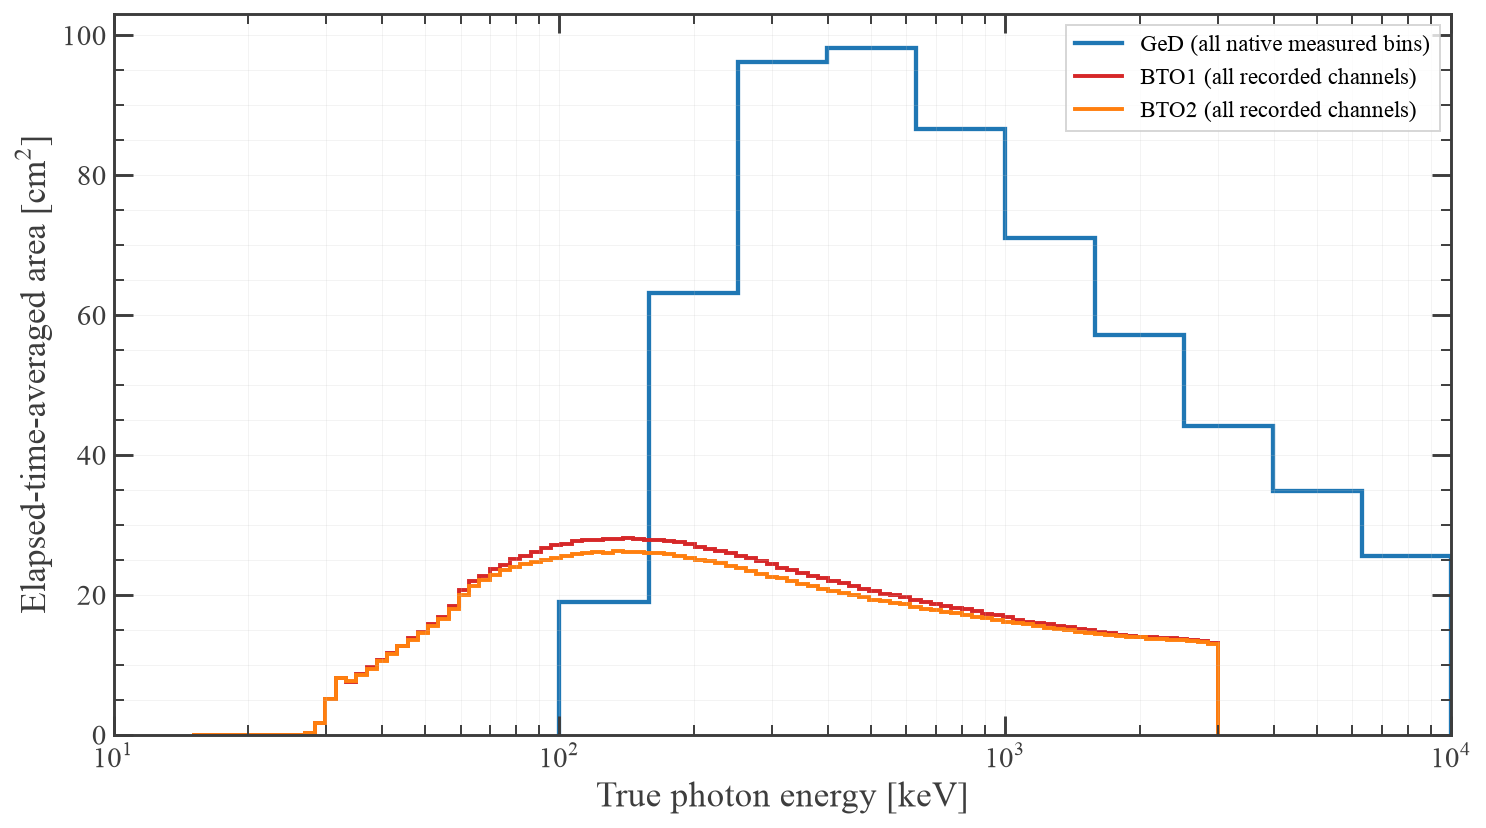

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 5.8), constrained_layout=True)
ax.stairs(ged_area_exposure_cm2_s.sum(axis=1)/duration_s, ei_edges,
          color='tab:blue', lw=2.2, label='GeD (all native measured bins)')
for detector_name in bto_ids:
    response = bto_responses[detector_name]
    ax.stairs(response.arf_cm2*visible_livetime_s/duration_s, response.photon_energy_edges_keV,
              color=detector_products[detector_name]['color'], lw=2,
              label=f'{detector_name} (all recorded channels)')
ax.set(xscale='log', xlim=(10,10000), ylim=(0,None), xlabel='True photon energy [keV]',
       ylabel=r'Elapsed-time-averaged area [cm$^2$]')
ax.grid(which='both', alpha=0.2)
ax.legend(frameon=True, fontsize=12)
style_axes(ax)
fig.savefig(output_path/'06_ged_bto_effective_area.png', dpi=300)
fig.savefig(output_path/'06_ged_bto_effective_area.pdf')
plt.show()

## 14. Select measured count windows and overplot the three detectors

Only complete native measured bins are included in a requested window. The
actual boundaries may differ slightly from a requested bound. The gray band and
dashed vertical edges show the GeD count window. The detector legend gives each
actual interval.

For BTO, display-only grouping sums neighboring ADC channels without losing a
remainder group. The left panel shows counts per displayed bin, whose widths
differ between detectors. The right panel divides by **elapsed time and displayed
bin width**, giving counts s$^{-1}$ keV$^{-1}$. Compare the rate-density panel when
comparing spectral amplitudes. The curves are expectations and have no sampled
Poisson error bars.

GeD requested / actual measured interval [keV]: (100.0, 10000.0) [100.0, 10000.0]
BTO1 requested / actual measured interval [keV]: (30.0, 2500.0) [30.0625, 2499.25]
BTO2 requested / actual measured interval [keV]: (30.0, 2500.0) [30.0625, 2499.25]


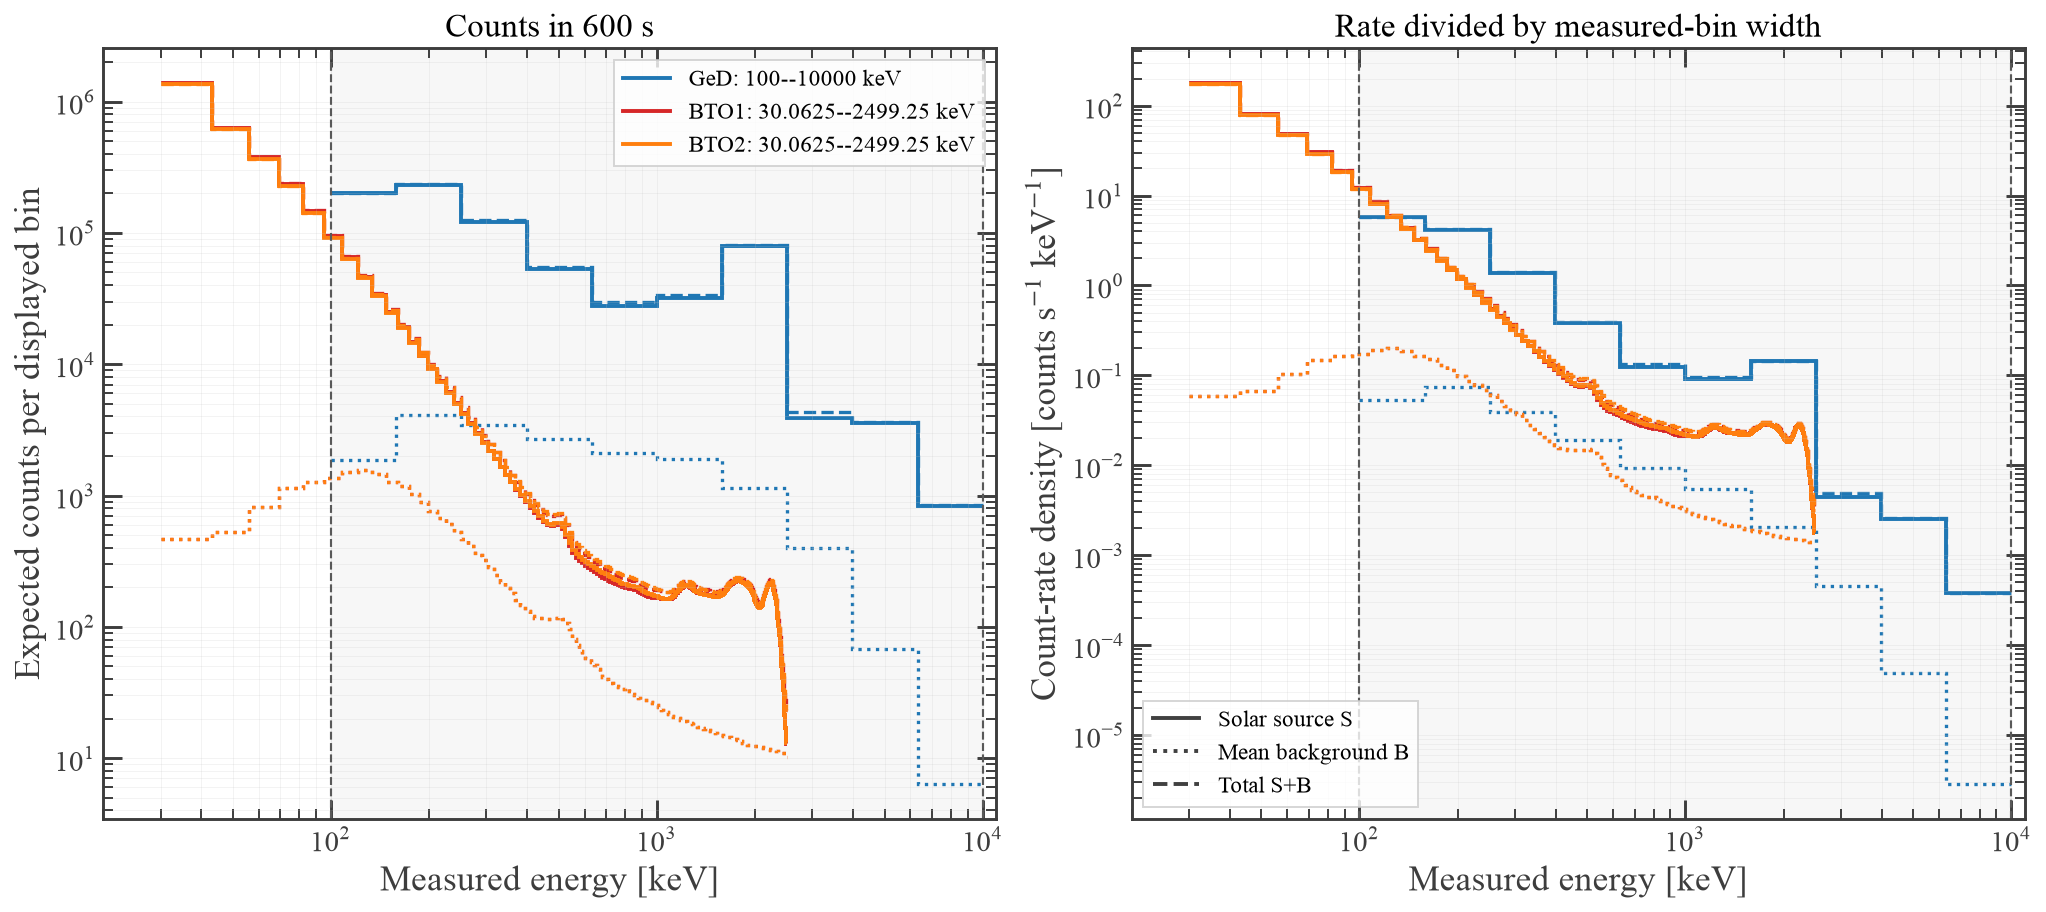

In [14]:
plot_series = []
for detector_name, product in detector_products.items():
    edges = product['edges']
    requested_low, requested_high = map(float, product['requested_range'])
    if not np.isfinite([requested_low,requested_high]).all() or requested_low >= requested_high:
        raise ValueError('Count windows must be finite increasing energy pairs')
    selected = ((edges[:-1] >= requested_low-1e-6) & (edges[1:] <= requested_high+1e-6))
    if not selected.any():
        raise ValueError(f'No complete measured-energy bins selected for {detector_name}')
    first, last = np.flatnonzero(selected)[[0,-1]]
    product['selected'] = selected
    product['actual_range'] = [float(edges[first]),float(edges[last+1])]
    group = 1 if detector_name == 'GeD' else bto_plot_group
    boundaries = np.unique(np.r_[np.arange(first,last+1,group),last+1]).astype(int)
    plotted = {'name':detector_name,'color':product['color'],'edges':edges[boundaries]}
    for component in ('source','background','total'):
        values = product[component][first:last+1]
        grouped = np.add.reduceat(values,boundaries[:-1]-first)
        np.testing.assert_allclose(grouped.sum(),product[component][selected].sum(),rtol=1e-12)
        plotted[component] = grouped
    plot_series.append(plotted)
    print(detector_name, 'requested / actual measured interval [keV]:',
          product['requested_range'],product['actual_range'])

fig, axes = plt.subplots(1,2,figsize=(14.5,6.4),constrained_layout=True)
for ax in axes:
    ax.axvspan(*detector_products['GeD']['actual_range'],color='0.7',alpha=0.10,zorder=0)
    for boundary in detector_products['GeD']['actual_range']:
        ax.axvline(boundary,color='0.35',ls='--',lw=1.1)
for item in plot_series:
    widths = np.diff(item['edges'])
    for component,linestyle,width in (('source','-',2.0),('background',':',1.7),('total','--',1.7)):
        counts = item[component]
        axes[0].stairs(counts,item['edges'],color=item['color'],ls=linestyle,lw=width,baseline=None)
        axes[1].stairs(counts/(duration_s*widths),item['edges'],
                       color=item['color'],ls=linestyle,lw=width,baseline=None)
detector_handles = [Line2D([0],[0],color=p['color'],lw=2,
                    label=f"{name}: {p['actual_range'][0]:g}--{p['actual_range'][1]:g} keV")
                    for name,p in detector_products.items()]
style_handles = [Line2D([0],[0],color='0.25',lw=2,ls=style,label=label)
                 for style,label in (('-','Solar source S'),(':','Mean background B'),('--','Total S+B'))]
axes[0].legend(handles=detector_handles,fontsize=12,frameon=True,loc='upper right')
axes[1].legend(handles=style_handles,fontsize=12,frameon=True,loc='lower left')
axes[0].set(ylabel='Expected counts per displayed bin',title=f'Counts in {duration_s:g} s')
axes[1].set(ylabel=r'Count-rate density [counts s$^{-1}$ keV$^{-1}$]',title='Rate divided by measured-bin width')
for ax in axes:
    ax.set(xscale='log',yscale='log',xlim=(20,11000),xlabel='Measured energy [keV]')
    ax.grid(which='both',alpha=0.2)
    style_axes(ax)
fig.savefig(output_path/'07_solar_ged_bto_count_spectrum_overlay.png',dpi=300)
fig.savefig(output_path/'07_solar_ged_bto_count_spectrum_overlay.pdf')
plt.show()

## 15. Report counts and rates

For each detector, sum its selected **native** channels. The main rate is
`counts / elapsed duration`; a second set divides by instrument livetime. The
windows differ between GeD and BTO, so each row explicitly reports its energy
range. The final combined table sums detector readouts; it does not deduplicate
coincident photons between detectors.

These are linear-model expected rates for the supplied solar spectrum. The
GeD background uses the three-month mean divided by its Time-bin span; set a
verified effective reference exposure in Section 2 when available. BTO uses the
same mean single-detector template separately for BTO1/BTO2. No orbit-dependent
background or rate-dependent detector correction is silently applied.

In [15]:
rate_rows = []
native_tables = []
for detector_name, product in detector_products.items():
    selected = product['selected']
    row = {'detector':detector_name,
           'measured_low_keV':product['actual_range'][0],
           'measured_high_keV':product['actual_range'][1],
           'selected_native_bins':int(selected.sum())}
    for component in ('source','background','total'):
        counts = float(product[component][selected].sum())
        row[f'{component}_counts'] = counts
        row[f'{component}_counts_per_elapsed_s'] = counts/duration_s
        row[f'{component}_counts_per_live_s'] = counts/livetime_s
    rate_rows.append(row)
    native_tables.append(pd.DataFrame({
        'detector':detector_name,'E_low_keV':product['edges'][:-1],
        'E_high_keV':product['edges'][1:],'selected':selected,
        'source_counts':product['source'],'background_counts':product['background'],
        'total_counts':product['total'],
    }))
rate_table = pd.DataFrame(rate_rows)
display(rate_table[['detector','measured_low_keV','measured_high_keV','source_counts',
                    'background_counts','total_counts','source_counts_per_elapsed_s',
                    'background_counts_per_elapsed_s','total_counts_per_elapsed_s']].round(5))
summed_rates = rate_table[[f'{c}_counts_per_elapsed_s' for c in ('source','background','total')]].sum()
print('GeD+BTO1+BTO2 summed detector-readout rates [counts / elapsed s]:')
display(summed_rates.to_frame('counts_per_elapsed_s').round(5))

# These exports are outputs; none of the calculations above reads a saved result.
rate_table.to_csv(output_path/'solar_count_rates.csv',index=False)
pd.concat(native_tables,ignore_index=True).to_csv(output_path/'solar_native_count_spectra.csv',index=False)
summary = {
    'tstart_utc':tstart.utc.isot,'tstop_utc':tstop.utc.isot,
    'elapsed_s':float(duration_s),'instrument_livetime_s':float(livetime_s),
    'source_visible_livetime_s':float(visible_livetime_s),'earth_occultation':bool(earth_occultation),
    'source_galactic_l_deg':float(source_coord.galactic.l.deg),
    'source_galactic_b_deg':float(source_coord.galactic.b.deg),
    'flare_scale':float(flare_scale),'rates':json.loads(rate_table.to_json(orient='records')),
    'summed_detector_rates_per_elapsed_s':summed_rates.to_dict(),
    'rate_model':'Expected linear counts; no Poisson draw, dead time or pile-up',
}
(output_path/'solar_count_summary.json').write_text(json.dumps(summary,indent=2)+chr(10))
print('Outputs:',output_path)

,detector,measured_low_keV,measured_high_keV,source_counts,background_counts,total_counts,source_counts_per_elapsed_s,background_counts_per_elapsed_s,total_counts_per_elapsed_s
0,GeD,100.0000,10000.00,7.539579e+05,17711.83680,7.716697e+05,1256.59651,29.51973,1286.11624
1,BTO1,30.0625,2499.25,3.176611e+06,24545.33568,3.201156e+06,5294.35091,40.90889,5335.25980
2,BTO2,30.0625,2499.25,3.101377e+06,24545.33568,3.125923e+06,5168.96214,40.90889,5209.87104


GeD+BTO1+BTO2 summed detector-readout rates [counts / elapsed s]:


,counts_per_elapsed_s
source_counts_per_elapsed_s,11719.90956
background_counts_per_elapsed_s,111.33751
total_counts_per_elapsed_s,11831.24708


Outputs: /Users/shunsaku/work/COSI/soft/cosipy.nonimaging/cosipy/nonimaging/bto/notebook_output/solar_counts


## References and changing the example

Rerun from Section 2 after changing the interval, scale or count windows.
The solar input model is independent of the observation date. For a longer flare,
use shorter time segments to update its celestial direction and spectrum.

- [COSIpy detector-response tutorial](https://cositools-cosipy.readthedocs.io/en/latest/tutorials/response/DetectorResponse.html)
- [COSIpy point-source response](https://github.com/cositools/cosipy/blob/main/cosipy/response/PointSourceResponse.py)
- [COSIpy spacecraft history](https://github.com/cositools/cosipy/blob/main/cosipy/spacecraftfile/spacecraft_file.py)
- Local model recipe: `response/solar_model_provenance/output_flux.pro`.